# Metamodel case generation

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from `Samoa.json` → `simulations`.

In [1]:
from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.simulation import lhs_cases as sim
from utils.simulation.snapwave_wrappers import SnapWaveMetaModelWrapper

## Configuration

In [2]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-metamodel
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
samples   : 50 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,11.216690,316.206282,43.113140,-0.272811
1,1,3.712687,199.846245,40.751622,3.162712
2,1,8.126114,283.878110,33.776908,2.304660
3,1,10.147675,7.194458,8.653189,-2.443490
4,1,12.162468,227.346580,3.460959,-2.276724


<Axes: xlabel='tp', ylabel='dir'>

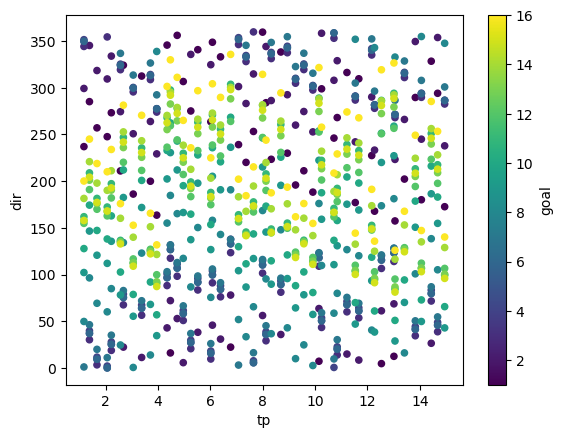

In [10]:
cases_df.plot.scatter(x="tp", y="dir", c="goal", cmap="viridis")

## SnapWave wrapper

In [5]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-07-07 12:36:29,891 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-07-07 12:36:29,891 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-07-07 12:36:29,892 - SnapWaveMetaModelWrapper - WARNING - Parameter dir is not in the default_parameters
2026-07-07 12:36:29,892 - SnapWaveMetaModelWrapper - WARNING - Parameter spr is not in the default_parameters
2026-07-07 12:36:29,892 - SnapWaveMetaModelWrapper - WARNING - Parameter wl is not in the default_parameters


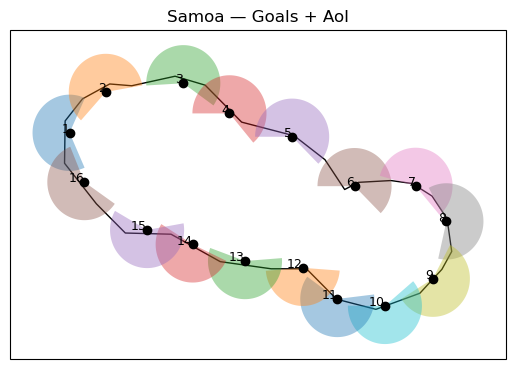

In [6]:
wrapper.plot_configuration()

In [7]:
wrapper.output_sites_df

,lon,lat,source,source_id,source_label,depth,name
0,-170.777083,-14.361964,isobath,5m_0,5m,-5.000000,NaN
1,-170.710720,-14.325416,isobath,5m_1,5m,-5.000000,NaN
2,-170.669192,-14.273447,isobath,5m_2,5m,-5.000000,NaN
3,-170.591440,-14.274576,isobath,5m_3,5m,-5.000000,NaN
4,-170.666803,-14.252163,isobath,5m_4,5m,-5.000000,NaN
...,...,...,...,...,...,...,...
723,-171.810368,-13.801214,mesh,Apia_17705,Apia,-11.782083,NaN
724,-171.718061,-13.851473,mesh,Apia_17721,Apia,-8.780432,NaN
725,-172.200000,-13.880000,buoy,buoy_Apolima_Buoy,waves,-80.000000,Savaii - Upolu middle buoy
726,-170.493000,-14.265000,buoy,buoy_American_Samoa_Buoy,waves,-75.000000,Ameican Samoa east buoy (Period 1)


## Build, run, postprocess

In [9]:
wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [10]:
wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [48]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    5500
Name: count, dtype: int64

In [49]:
wrapper.postprocess_cases()

'Done'